# Simulación CPPI Oro 2026

Estrategia CPPI (*Constant Proportion Portfolio Insurance*) en dólares: el activo riesgoso es el
**oro (USD)** y el activo seguro es el T-Bill de 3 meses del Tesoro de EE. UU.

**Fuente de datos (Yahoo Finance):**

| Ticker | Serie | Uso |
|---|---|---|
| `GC=F`  | Futuro de oro COMEX (mes frontal), USD/oz | Precio del oro (mejor aproximación a XAU spot en Yahoo; `XAUUSD=X` ya no se publica) |
| `GLD`   | SPDR Gold Shares ETF, USD | Instrumento invertible |
| `^IRX`  | Rendimiento T-Bill 13 semanas (%) | Activo libre de riesgo |

El activo central del cuaderno es **Oro (USD)** = `GC=F`. Todas las cifras están en USD.
Si no hay conexión, los precios se leen de la copia guardada en `data/precios_oro.csv`.

### Bibliotecas y configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import yfinance as yf
import datetime as dt
from pathlib import Path

import Optiport as op   # corre_cppi, run_cppi, gbm, drawdown
import aqmRisk as aqm   # summary_stats

%load_ext autoreload
%autoreload 2

# Interactividad
import ipywidgets as widgets
from ipywidgets import interact
from IPython.display import display

plt.rcParams['figure.figsize'] = (12, 6)

### Parámetros generales

In [2]:
INICIO = '2005-01-01'
FIN = None                         # None = hasta el último dato disponible
CACHE = Path('data/precios_oro.csv')

tickers = {'GC=F': 'Oro (USD)', 'GLD': 'GLD (USD)', '^IRX': 'T-Bill 3M'}
ACTIVO = 'Oro (USD)'          # Activo riesgoso central del cuaderno

# Parámetros CPPI
start = 1000                       # Valor inicial del portafolio
floor = 0.95                       # Piso como % del valor inicial
m = 3                              # Multiplicador
trans_cost = 0.075 / 100           # Costo de transacción sobre el monto rebalanceado
fee_anual = 0.02                   # Comisión de administración anual

## ETL
Descarga diaria de Yahoo Finance; si falla o tarda más de 60 s se usa la copia local.

In [3]:
import threading

def descarga_precios(tickers, inicio, fin=None, cache=CACHE, limite=60):
    res = {}
    def _dl():
        res['px'] = yf.download(list(tickers), start=inicio, end=fin, progress=False, auto_adjust=True,
                                threads=False, timeout=30)['Close']
    try:
        hilo = threading.Thread(target=_dl, daemon=True)
        hilo.start()
        hilo.join(limite)
        px = res.get('px')
        if px is None or px.dropna(how='all').empty:
            raise ValueError('descarga vacía')
        cache.parent.mkdir(exist_ok=True)
        px.to_csv(cache)
        print(f'Datos descargados de Yahoo Finance hasta {px.index.max():%Y-%m-%d}; copia guardada en {cache}')
    except Exception as e:
        px = pd.read_csv(cache, index_col=0, parse_dates=True)
        print(f'Sin descarga ({e}); usando {cache} (hasta {px.index.max():%Y-%m-%d})')
    return px[list(tickers)]

px_diario = descarga_precios(tickers, INICIO, FIN)
px_diario = px_diario.rename(columns=tickers).ffill().dropna()
px_diario.tail()

Datos descargados de Yahoo Finance hasta 2026-11-20; copia guardada en data/precios_oro.csv


Ticker,Oro (USD),GLD (USD),T-Bill 3M
Date,,,
2026-11-16,3853.000000,352.929993,4.125
2026-11-17,3864.199951,352.480011,4.138
2026-11-18,3741.899902,341.190002,4.145
2026-11-19,3685.500000,335.179993,4.147
2026-11-20,3515.399902,322.869995,4.122


### Precios mensuales
El CPPI se rebalancea mensualmente (12 pasos por año, consistente con la simulación Montecarlo).

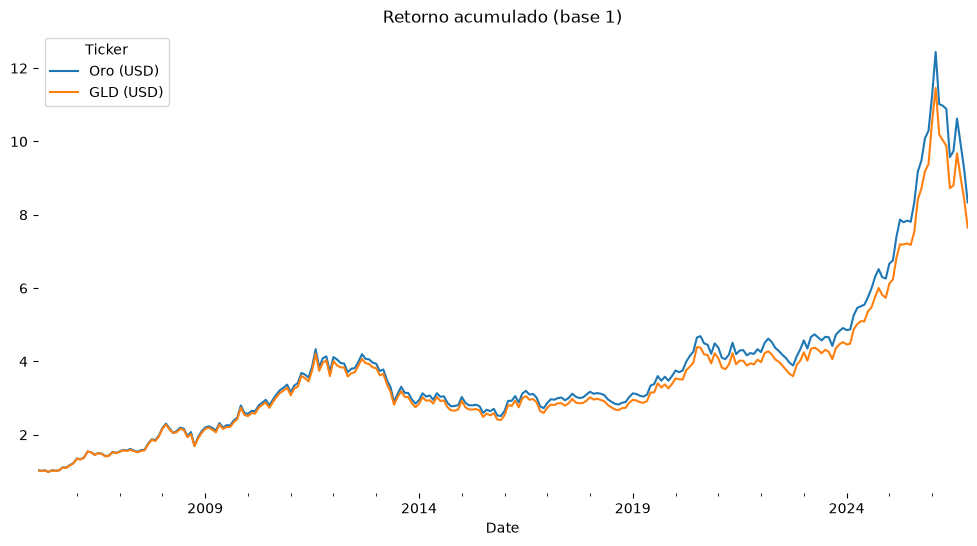

In [4]:
mensual = px_diario.resample('ME').last()
prices = mensual[['Oro (USD)', 'GLD (USD)']]
tbill = mensual['T-Bill 3M']                     # Rendimiento anual en %

returns = prices.pct_change().dropna()
cumret = (1 + returns).cumprod()

ax = cumret.plot()
ax.set_title('Retorno acumulado (base 1)')
plt.box(on=None)
plt.savefig('Oro_Activos.png', bbox_inches='tight')
plt.show()

### Activo libre de riesgo: T-Bill de 3 meses
El retorno del mes *t* usa el rendimiento observado al cierre del mes *t-1*, que es la tasa conocida
al momento de invertir: $r_t = (1 + y_{t-1})^{1/12} - 1$.

In [5]:
safe_r = ((1 + tbill.shift(1) / 100)**(1/12) - 1).reindex(returns.index)
rf_anual = (1 + safe_r.mean())**12 - 1
print(f'Último rendimiento T-Bill 3M: {tbill.iloc[-1]:.2f}%')
print(f'T-Bill promedio anualizado en la muestra: {rf_anual:.2%}')

Último rendimiento T-Bill 3M: 4.12%
T-Bill promedio anualizado en la muestra: 1.75%


### Estadísticas de los activos (mensuales)

In [6]:
aqm.summary_stats(returns, riskfree_rate=rf_anual, freq='MONTHLY') \
   .sort_values('Annualized Sharpe Ratio', ascending=False)

,Annualized Return,Annualized Vol,Annualized Sharpe Ratio,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Gaussian VaR,Max Drawdown
Ticker,,,,,,,,,
Oro (USD),0.101989,0.174032,0.477423,-0.156642,3.445010,0.074854,0.098338,0.073095,-0.420126
GLD (USD),0.097656,0.174675,0.451250,-0.015845,3.149608,0.073802,0.095697,0.073727,-0.429102


### Cálculo del Maximum Drawdown

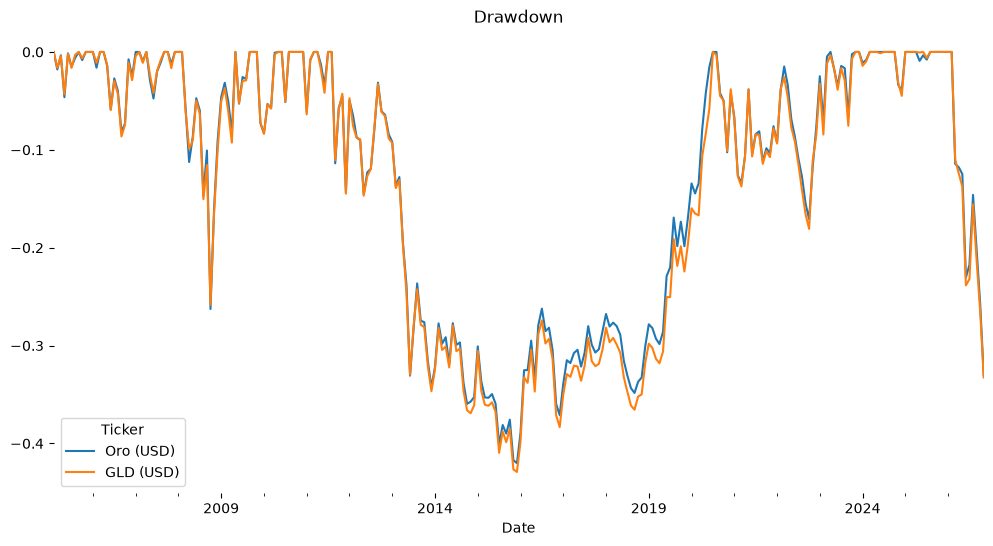

Ticker
Oro (USD)   -0.420126
GLD (USD)   -0.429102
dtype: float64

In [7]:
max_previo = cumret.cummax()
drawdown = (cumret - max_previo) / max_previo
drawdown.plot(title='Drawdown')
plt.box(on=None)
plt.savefig('Drawdown_Oro.png', bbox_inches='tight')
plt.show()
drawdown.min()

## Backtesting CPPI sobre el oro
### Indicamos que el activo riesgoso es el oro

In [8]:
datos = pd.concat([returns, safe_r.rename('T-Bill 3M')], axis=1).dropna()
risky_r = datos.drop(columns='T-Bill 3M')
safe_r = datos['T-Bill 3M']
print(f'Backtest: {risky_r.index.min():%Y-%m} a {risky_r.index.max():%Y-%m} ({len(risky_r)} meses)')
risky_r.tail()

Backtest: 2005-02 a 2026-11 (262 meses)


,Oro (USD),GLD (USD)
Date,,
2026-07-31,0.016962,0.008578
2026-08-31,0.091186,0.099263
2026-09-30,-0.065782,-0.067529
2026-10-31,-0.068742,-0.065802
2026-11-30,-0.098361,-0.092501


## El algoritmo implica 3 procesos principales:
1. Cálculo del colchón (valor del portafolio menos el piso)
2. Asignación a los activos riesgoso y seguro --> m × colchón
3. Recálculo del valor del portafolio con base en los retornos

### Ciclo de backtesting
Aplicamos el algoritmo a cada serie de oro con el T-Bill como activo seguro, comisión de administración
y costos de transacción.

In [9]:
dates = risky_r.index
n_steps = len(dates)
account_value = start
floor_value = start * floor
account_history = pd.DataFrame().reindex_like(risky_r)
cushion_history = pd.DataFrame().reindex_like(risky_r)
risky_w_history = pd.DataFrame().reindex_like(risky_r)
transaction_cost_history = pd.DataFrame().reindex_like(risky_r)
risky_alloc = 0
for step in range(n_steps):
    cushion = (account_value - floor_value) / account_value
    risky_w = m * cushion
    risky_w = np.minimum(risky_w, 1)
    risky_w = np.maximum(risky_w, 0)
    safe_w = 1 - risky_w
    risky_prev = risky_alloc
    risky_alloc = account_value * risky_w
    safe_alloc = account_value * safe_w
    transaction_cost = abs(risky_alloc - risky_prev) * trans_cost
    # Comisión mensual de administración
    fees = account_value * ((1 + fee_anual)**(1/12) - 1)
    # Actualiza el valor de la cuenta
    account_value = (risky_alloc * (1 + risky_r.iloc[step]) + safe_alloc * (1 + safe_r.iloc[step])
                     - transaction_cost - fees)
    # Guarda los valores para visualizarlos después
    cushion_history.iloc[step] = cushion
    risky_w_history.iloc[step] = risky_w
    account_history.iloc[step] = account_value
    transaction_cost_history.iloc[step] = transaction_cost

long_only = start * (1 + risky_r).cumprod()
account_history.tail()

,Oro (USD),GLD (USD)
Date,,
2026-07-31,3477.159336,3143.283793
2026-08-31,3788.444952,3450.086754
2026-09-30,3532.744961,3211.179148
2026-10-31,3283.872179,2994.394737
2026-11-30,2955.256733,2712.302171


### El backtest muestra lo que habría sido el comportamiento de la estrategia

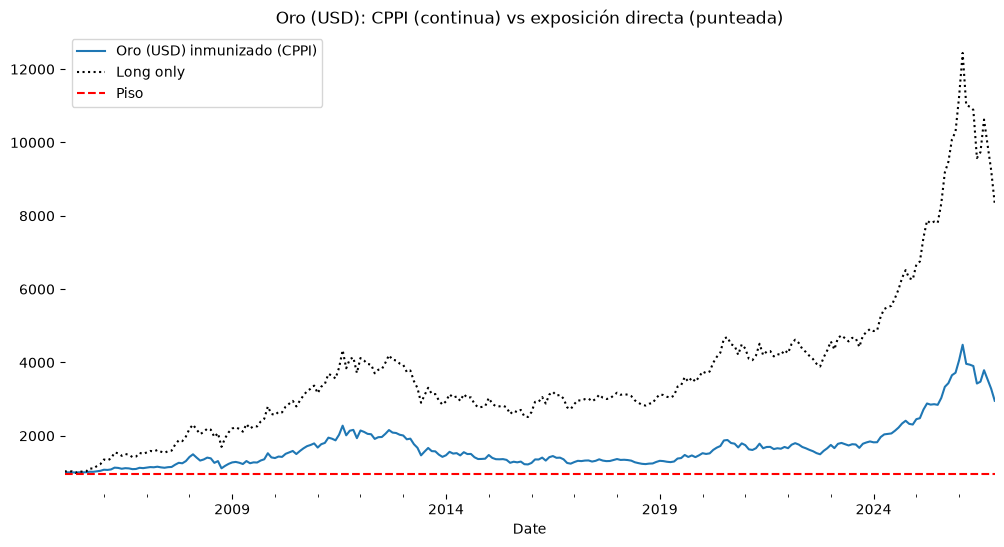

In [10]:
ax = account_history[ACTIVO].plot(figsize=(12, 6), legend=True)
long_only[ACTIVO].plot(ax=ax, style='k:', legend=True)
ax.axhline(y=floor_value, color='r', linestyle='--')
plt.legend([f'{ACTIVO} inmunizado (CPPI)', 'Long only', 'Piso'])
plt.box(on=None)
plt.title(f'{ACTIVO}: CPPI (continua) vs exposición directa (punteada)')
plt.savefig('CPPI_Oro.png', bbox_inches='tight')
plt.show()

### Ponderaciones históricas del activo riesgoso en el portafolio

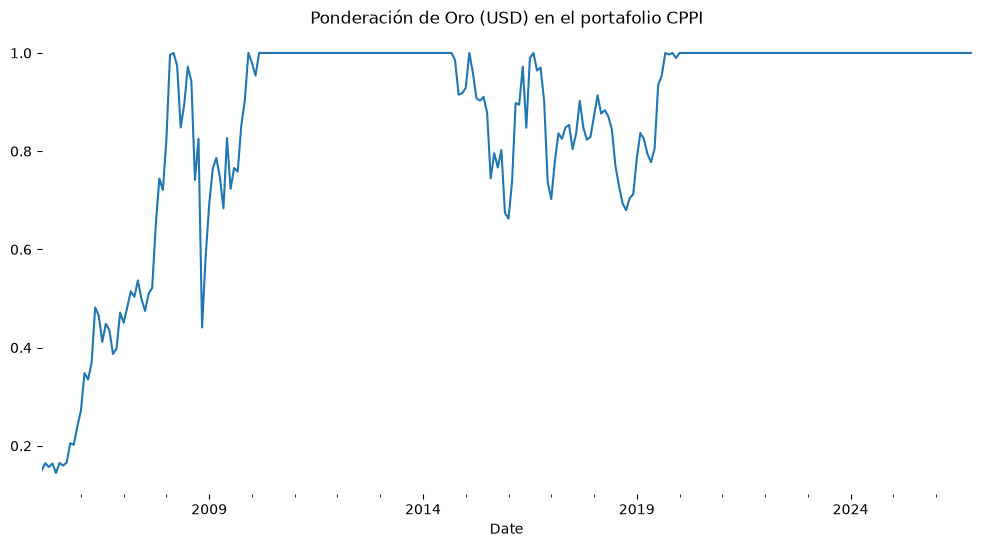

In [11]:
risky_w_history[ACTIVO].plot(title=f'Ponderación de {ACTIVO} en el portafolio CPPI')
plt.box(on=None)
plt.show()

### Backtest con `Optiport.corre_cppi`
Mismo algoritmo, sin comisión de administración, con el T-Bill como activo seguro.

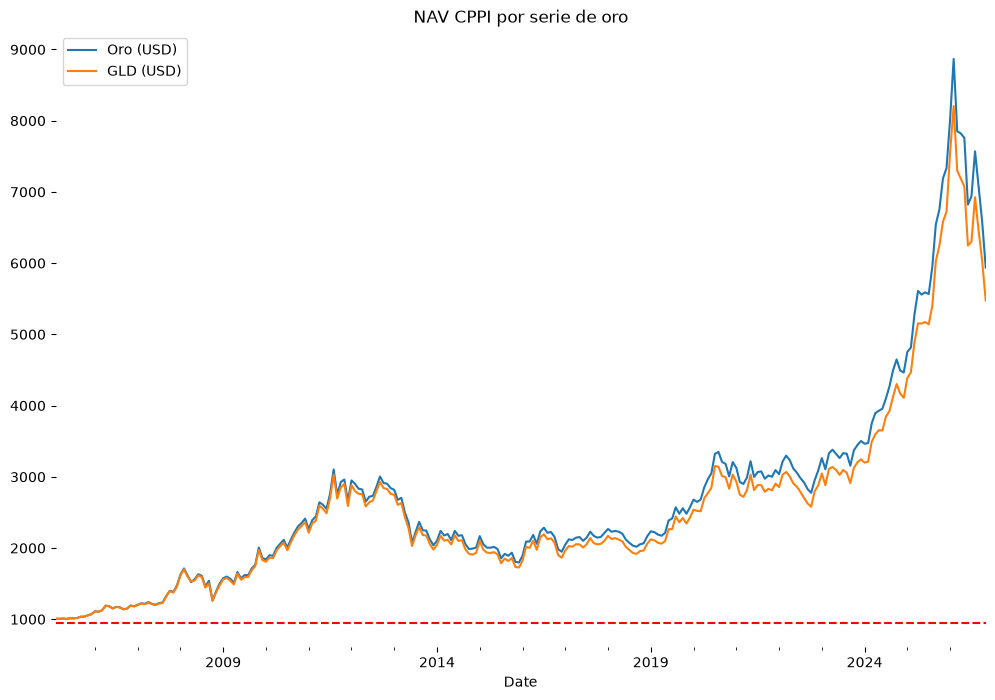

In [12]:
safe_df = pd.DataFrame({c: safe_r for c in risky_r.columns})
btr = op.corre_cppi(risky_r, safe_r=safe_df, m=m, start=start, floor=floor, trans_cost=trans_cost)

nav = btr['CPPI_NAV'].astype(float)
ax = nav.plot(figsize=(12, 8), title='NAV CPPI por serie de oro')
ax.axhline(y=start * floor, color='r', linestyle='--')
plt.box(on=None)
plt.show()

### CPPI vs Buy & Hold: estadísticas

In [13]:
comp = pd.concat({'CPPI': nav[ACTIVO], 'Buy&Hold': btr['buy&hold'][ACTIVO]}, axis=1)
comp_r = comp.pct_change()
comp_r.iloc[0] = comp.iloc[0] / start - 1
aqm.summary_stats(comp_r, riskfree_rate=rf_anual, freq='MONTHLY')

,Annualized Return,Annualized Vol,Annualized Sharpe Ratio,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Gaussian VaR,Max Drawdown
CPPI,0.085000,0.165961,0.399903,-0.253721,3.704159,0.073394,0.098378,0.070683,-0.421085
Buy&Hold,0.101989,0.174032,0.477423,-0.156642,3.445010,0.074854,0.098338,0.073095,-0.420126


# Restricción al drawdown
El piso se recalcula como el 90% del máximo histórico del portafolio (drawdown máximo del 10%).
Reduce la rentabilidad esperada pero protege las ganancias acumuladas.

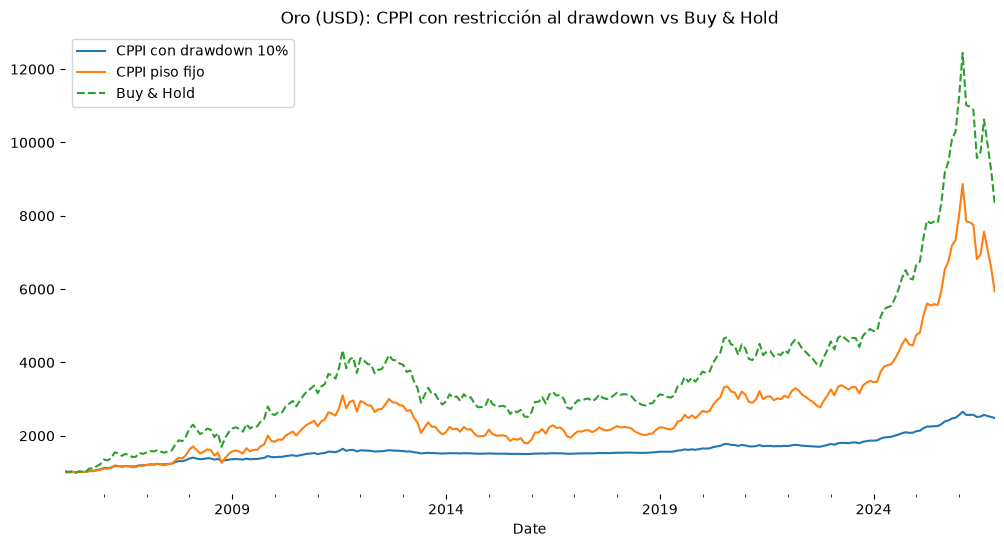

In [14]:
btr_capped = op.corre_cppi(risky_r[[ACTIVO]], safe_r=safe_df[[ACTIVO]], m=m, start=start,
                           floor=floor, trans_cost=trans_cost, drawdown=0.10)
ax = btr_capped['CPPI_NAV'][ACTIVO].astype(float).plot(figsize=(12, 6), label='CPPI con drawdown 10%')
nav[ACTIVO].plot(ax=ax, label='CPPI piso fijo')
btr_capped['buy&hold'][ACTIVO].plot(ax=ax, style='--', label='Buy & Hold')
plt.title(f'{ACTIVO}: CPPI con restricción al drawdown vs Buy & Hold')
plt.box(on=None)
ax.legend(loc='upper left')
plt.show()

# Simulación Montecarlo
Implementamos simulación de Montecarlo (Movimiento Browniano Geométrico) para validar la probabilidad
de violar el piso.

### Calibración del modelo y análisis de escenarios
Los riesgos principales son un incremento en la volatilidad que genere una caída en el valor del activo
riesgoso, acompañado de una imposibilidad de rebalancear.

In [15]:
mu = (1 + risky_r[ACTIVO]).prod()**(12 / len(risky_r)) - 1    # Retorno anual compuesto
sigma = risky_r[ACTIVO].std() * np.sqrt(12)                    # Volatilidad anual
MDD = op.drawdown(risky_r[ACTIVO])['Drawdown'].min()           # Maximum drawdown histórico
s_0 = prices[ACTIVO].iloc[-1]

print(f'{ACTIVO}: mu={mu:.2%}  sigma={sigma:.2%}  MDD={MDD:.2%}  último precio=US${s_0:,.2f}')

Oro (USD): mu=10.20%  sigma=17.40%  MDD=-42.01%  último precio=US$3,515.40


# Calibración para el CPPI
Evaluación de sensibilidades por parámetro. Los valores iniciales de los controles son los calibrados
arriba para el oro (USD) y el T-Bill promedio.

In [16]:
def show_cppi(inicio=1000, n_years=5, n_scenarios=1000, mu=0.1, sigma=0.2, m=3, piso=0.9, rf=0.06, y_max=1000):
    """Grafica el resultado de la simulación del CPPI"""
    start = inicio
    sim_rets = op.gbm(n_years=n_years, n_scenarios=n_scenarios, mu=mu, sigma=sigma, prices=False, steps_per_year=12)
    # Corre el backtest
    btr = op.run_cppi(risky_r=pd.DataFrame(sim_rets), riskfree_rate=rf, m=m, start=start, floor=piso, drawdown=None)
    wealth = btr['Wealth']
    y_max = wealth.values.max() * y_max / 1000
    # Valores terminales
    terminal_wealth = wealth.iloc[-1]
    fig, (wealth_ax, hist_ax) = plt.subplots(nrows=1, ncols=2, sharey=True,
                                             gridspec_kw={'width_ratios': [3, 2]}, figsize=(24, 9))
    plt.subplots_adjust(wspace=0)
    wealth.plot(ax=wealth_ax, legend=False, alpha=0.3, color='goldenrod')
    wealth_ax.axhline(y=start, ls=':', color='black')
    wealth_ax.axhline(y=start * piso, ls='--', color='red')
    wealth_ax.set_ylim(top=y_max)

    terminal_wealth.plot.hist(ax=hist_ax, bins=50, ec='w', fc='goldenrod', orientation='horizontal')
    tw_mean = terminal_wealth.mean()
    tw_median = terminal_wealth.median()
    failure_mask = np.less(terminal_wealth, inicio * piso)
    n_failures = failure_mask.sum()
    p_fail = n_failures / n_scenarios
    e_shortfall = np.dot(terminal_wealth - inicio * piso, failure_mask) / n_failures if n_failures > 0 else 0.0

    hist_ax.axhline(y=start, ls=':', color='black', linewidth=4)
    hist_ax.axhline(y=tw_median, ls=':', color='purple', linewidth=4)
    hist_ax.axhline(y=tw_mean, ls=':', color='indianred', linewidth=4)
    hist_ax.annotate(f'Promedio: ${int(tw_mean)}', xy=(.5, .9), xycoords='axes fraction', fontsize=20)
    hist_ax.annotate(f'Mediana: ${int(tw_median)}', xy=(.5, .85), xycoords='axes fraction', fontsize=20)
    if piso > 0.01:
        hist_ax.axhline(y=inicio * piso, ls='--', color='red', linewidth=4)
        hist_ax.annotate(f'Violaciones: {n_failures} ({p_fail*100:2.2f}%)\nE(shortfall)=${e_shortfall:2.2f}',
                         xy=(.5, .7), xycoords='axes fraction', fontsize=20)
    plt.show()

### Escenario base calibrado (estático)

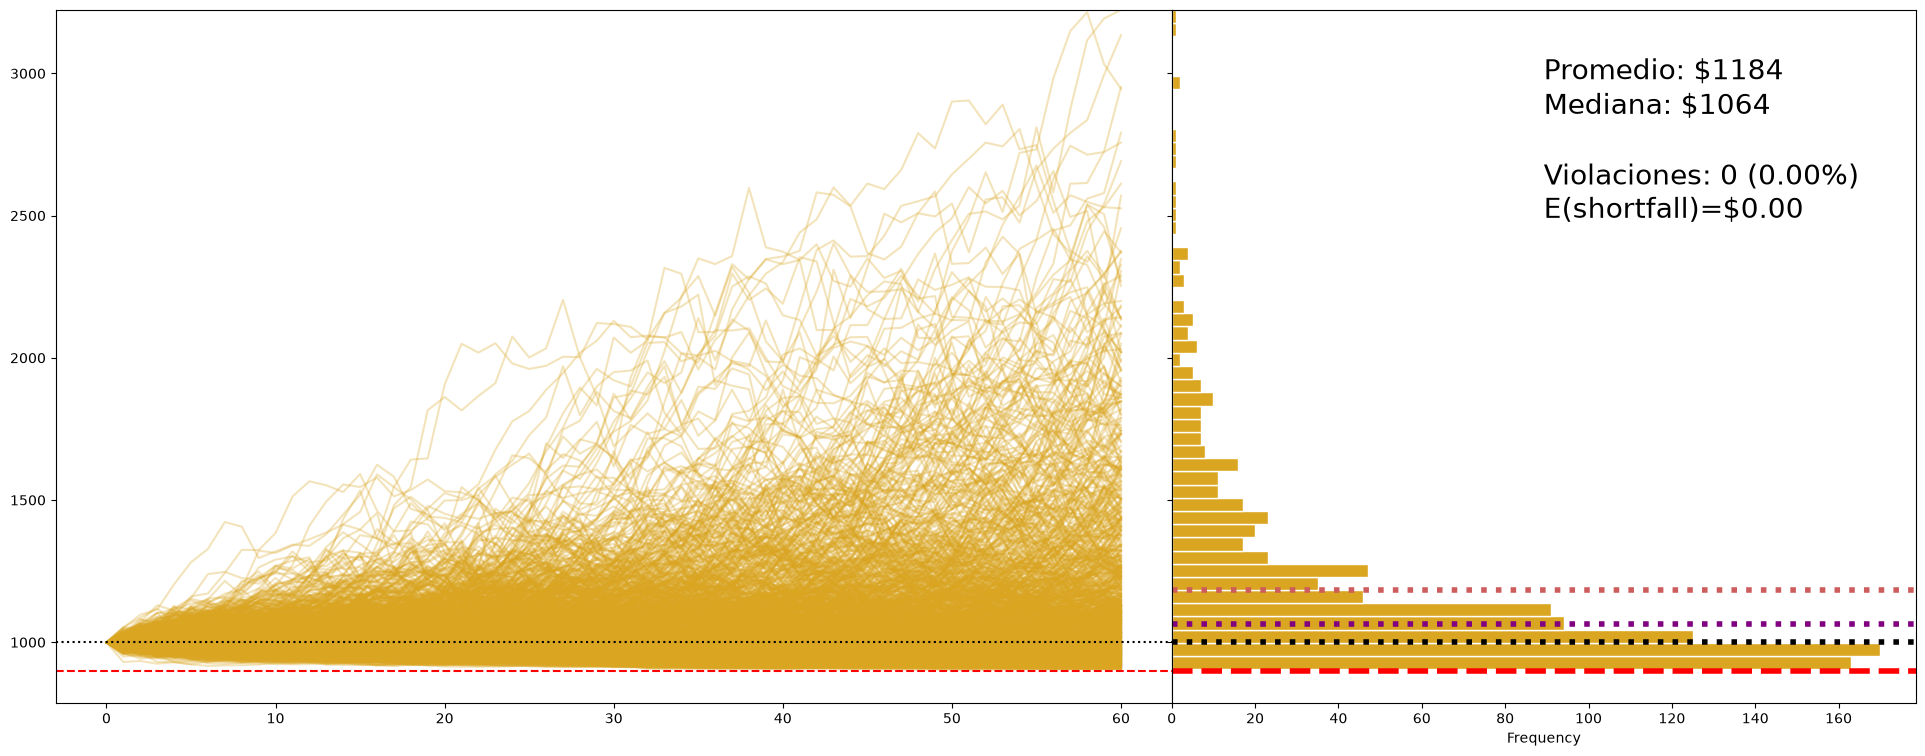

In [17]:
np.random.seed(2026)
show_cppi(mu=round(mu, 2), sigma=round(sigma, 3), m=m, piso=0.9, rf=round(rf_anual, 2))

### Simulación interactiva (requiere kernel activo)
Ajuste los parámetros y presione **Simular**.

In [18]:
controles_cppi = widgets.interactive(show_cppi, {'manual': True, 'manual_name': 'Simular'},
                                     inicio=widgets.fixed(1000),
                                     n_years=widgets.IntSlider(min=1, max=10, step=1, value=5),
                                     n_scenarios=widgets.IntSlider(min=1, max=1000, step=5, value=1000),
                                     mu=widgets.FloatSlider(min=-0.1, max=0.3, step=0.01, value=round(mu, 2)),
                                     sigma=widgets.FloatSlider(min=0, max=0.5, step=0.005, value=round(sigma, 3)),
                                     piso=(0.5, 1.2, .05),
                                     m=(1, 5, 0.5),
                                     rf=widgets.FloatSlider(min=0, max=0.10, step=0.005, value=round(rf_anual, 3)),
                                     y_max=widgets.IntSlider(min=0, max=3000, step=100, value=1000,
                                                             description='Zoom Eje Y'))
display(controles_cppi)

interactive(children=(IntSlider(value=5, description='n_years', max=10, min=1), IntSlider(value=1000, descript…